# Modelo Supervisionado - Arquivo Jupyter para separação de código

In [40]:
def avaliar_modelo(modelo, x_teste, y_teste, nome_modelo="Modelo"):
    # 1. O modelo gera suas próprias predições isoladamente
    y_pred = modelo.predict(x_teste)
    
    # 2. Relatório de Classificação
    print(f"\n--- Relatório de Classificação: {nome_modelo} ---")
    print(classification_report(y_teste, y_pred))
    
    # 3. Construção da Matriz de Confusão
    matriz = confusion_matrix(y_teste, y_pred)
    grafico = ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=modelo.classes_)
    
    # 4. Plotagem do Gráfico
    grafico.plot(cmap='Blues', values_format='d')
    plt.title(f"Matriz de Confusão - {nome_modelo}")
    plt.xticks(rotation=45)
    plt.show()

## Imports de bibliotecas

In [56]:
import pandas as pd
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt 
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

## Separação de dados

In [4]:
dados_teste = pd.read_csv('../02_dados_tratados/dados_clusterizados_rotulados.csv')


x = dados_teste[["idade","renda_mensal","compras_mes","ticket_medio","engajamento_fidelidade"]]
y = dados_teste["rotulo_grupo"]

x_treino, x_teste, y_treino, y_teste = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

padronizador = StandardScaler()

x_treino_padronizado = padronizador.fit_transform(x_treino)

x_teste_padronizado = padronizador.transform(x_teste)


## Modelo de 50 iterações

### Estrutura do Modelo

In [57]:
modelo50 = MLPClassifier(
    hidden_layer_sizes = (5,),
    max_iter = 50,
    tol = 0,
    random_state = 42,
    verbose = True
)

modelo50.fit(x_treino_padronizado, y_treino)

y_pred_treino = modelo50.predict(x_treino_padronizado)
acuraciaTreino = accuracy_score(y_treino, y_pred_treino)
print(f"Acurácia de treino do Modelo: {acuraciaTreino: .2%}")

y_pred_teste = modelo50.predict(x_teste_padronizado)
acuracia = accuracy_score(y_teste, y_pred_teste)
print(f"Acurácia de teste do Modelo: {acuracia: .2%}")

Iteration 1, loss = 1.53098985
Iteration 2, loss = 1.31757363
Iteration 3, loss = 1.15068013
Iteration 4, loss = 1.02367016
Iteration 5, loss = 0.92627297
Iteration 6, loss = 0.85258513
Iteration 7, loss = 0.79580347
Iteration 8, loss = 0.75063351
Iteration 9, loss = 0.71261073
Iteration 10, loss = 0.67884452
Iteration 11, loss = 0.64695403
Iteration 12, loss = 0.61483222
Iteration 13, loss = 0.58076254
Iteration 14, loss = 0.54338484
Iteration 15, loss = 0.50344976
Iteration 16, loss = 0.46402681
Iteration 17, loss = 0.42864728
Iteration 18, loss = 0.39840589
Iteration 19, loss = 0.37255417
Iteration 20, loss = 0.34987064
Iteration 21, loss = 0.32937225
Iteration 22, loss = 0.31060451
Iteration 23, loss = 0.29315600
Iteration 24, loss = 0.27685989
Iteration 25, loss = 0.26156238
Iteration 26, loss = 0.24723536
Iteration 27, loss = 0.23366173
Iteration 28, loss = 0.22094664
Iteration 29, loss = 0.20893365
Iteration 30, loss = 0.19770803
Iteration 31, loss = 0.18711438
Iteration 32, los

c:\Users\asasd\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(



--- Detalhes do Treinamento ---
Quantidade real de iterações: 50
Perda final (loss): 0.082434


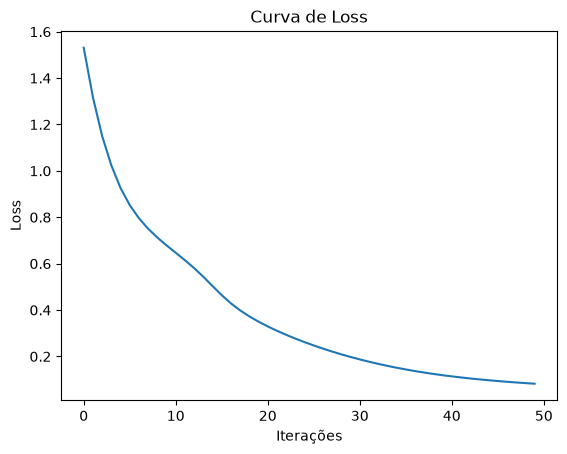

In [48]:
# Atributos de treinamento (disponíveis apenas APÓS o modelo.fit)
print(f"\n--- Detalhes do Treinamento ---")
print(f"Quantidade real de iterações: {modelo50.n_iter_}")
print(f"Perda final (loss): {modelo50.loss_:.6f}")

plt.plot(modelo50.loss_curve_)
plt.xlabel("Iterações")
plt.ylabel("Loss")
plt.title("Curva de Loss")
plt.show()

### Matriz de Confusão


--- Relatório de Classificação: MLP 50 Iterações ---
                         precision    recall  f1-score   support

    perfil_alto_consumo       0.99      1.00      1.00       377
perfil_baixa_frequencia       0.99      1.00      0.99       615
     perfil_equilibrado       1.00      0.98      0.99       608

               accuracy                           0.99      1600
              macro avg       0.99      0.99      0.99      1600
           weighted avg       0.99      0.99      0.99      1600



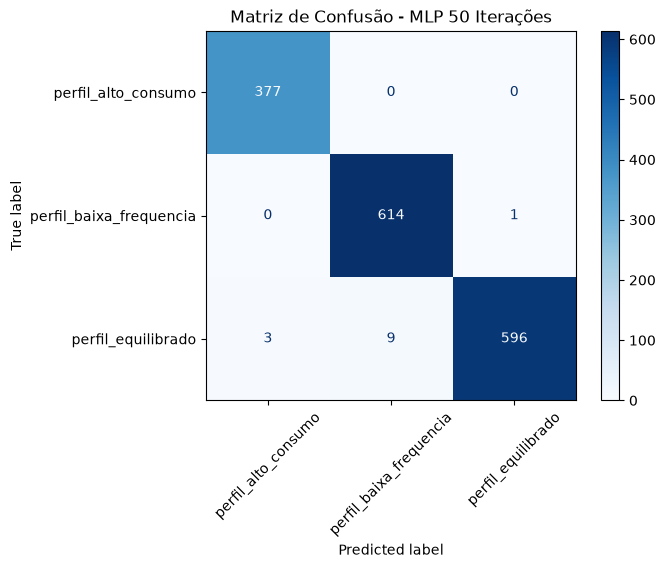

In [49]:
avaliar_modelo(modelo50, x_teste_padronizado, y_teste, nome_modelo="MLP 50 Iterações")

## Modelo de 500 iterações

### Estrutura do Modelo

In [51]:
modelo500 = MLPClassifier(
    hidden_layer_sizes = (5,),
    max_iter = 500,
    tol = 0,
    random_state = 42,
    verbose = True
)

modelo500.fit(x_treino_padronizado, y_treino)

y_pred_treino = modelo500.predict(x_treino_padronizado)
acuraciaTreino = accuracy_score(y_treino, y_pred_treino)
print(f"Acurácia de treino do Modelo: {acuraciaTreino: .2%}")

y_pred_teste = modelo500.predict(x_teste_padronizado)
acuracia = accuracy_score(y_teste, y_pred_teste)
print(f"Acurácia de teste do Modelo: {acuracia: .2%}")


Iteration 1, loss = 1.53098985
Iteration 2, loss = 1.31757363
Iteration 3, loss = 1.15068013
Iteration 4, loss = 1.02367016
Iteration 5, loss = 0.92627297
Iteration 6, loss = 0.85258513
Iteration 7, loss = 0.79580347
Iteration 8, loss = 0.75063351
Iteration 9, loss = 0.71261073
Iteration 10, loss = 0.67884452
Iteration 11, loss = 0.64695403
Iteration 12, loss = 0.61483222
Iteration 13, loss = 0.58076254
Iteration 14, loss = 0.54338484
Iteration 15, loss = 0.50344976
Iteration 16, loss = 0.46402681
Iteration 17, loss = 0.42864728
Iteration 18, loss = 0.39840589
Iteration 19, loss = 0.37255417
Iteration 20, loss = 0.34987064
Iteration 21, loss = 0.32937225
Iteration 22, loss = 0.31060451
Iteration 23, loss = 0.29315600
Iteration 24, loss = 0.27685989
Iteration 25, loss = 0.26156238
Iteration 26, loss = 0.24723536
Iteration 27, loss = 0.23366173
Iteration 28, loss = 0.22094664
Iteration 29, loss = 0.20893365
Iteration 30, loss = 0.19770803
Iteration 31, loss = 0.18711438
Iteration 32, los

c:\Users\asasd\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(



--- Detalhes do Treinamento ---
Quantidade real de iterações: 500
Perda final (loss): 0.007805


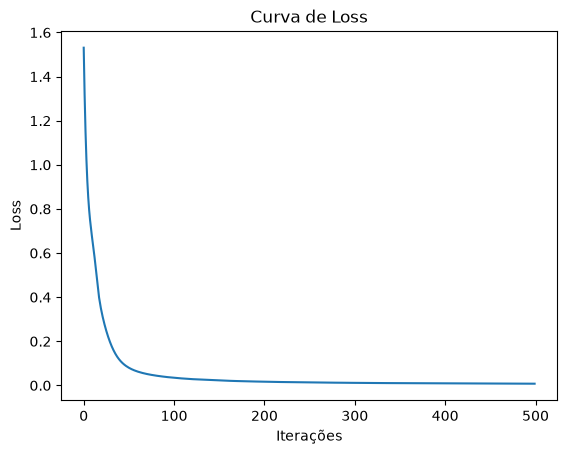

In [32]:
# Atributos de treinamento (disponíveis apenas APÓS o modelo.fit)
print(f"\n--- Detalhes do Treinamento ---")
print(f"Quantidade real de iterações: {modelo500.n_iter_}")
print(f"Perda final (loss): {modelo500.loss_:.6f}")

plt.plot(modelo500.loss_curve_)
plt.xlabel("Iterações")
plt.ylabel("Loss")
plt.title("Curva de Loss")
plt.show()

### Teste de predição do modelo

In [55]:
novos_compradores = [
    {"idade": 40, "renda_mensal": 3001.55, "compras_mes": 4, "ticket_medio": 5.0, "engajamento_fidelidade": 30.3}, # Deve retornar perfil_baixa_frequencia
    {"idade": 46, "renda_mensal": 6809.31, "compras_mes": 9, "ticket_medio": 171.51, "engajamento_fidelidade": 70.3}, # Deve retornar perfil_equilibrado
    {"idade": 30, "renda_mensal": 3000.00, "compras_mes": 5, "ticket_medio": 500.00, "engajamento_fidelidade": 20.0}, # Deve retornar perfil_equilibrado
    {"idade": 70, "renda_mensal": 3000.00, "compras_mes": 7, "ticket_medio": 500.00, "engajamento_fidelidade": 50.0}, # Deve retornar perfil_alto_consumo
    {"idade": 90, "renda_mensal": 3000.00, "compras_mes": 7, "ticket_medio": 600.00, "engajamento_fidelidade": 10.0} # Deve retornar perfil_alto_consumo
]


df_novos_compradores = pd.DataFrame(novos_compradores)


compradores_padronizados = padronizador.transform(df_novos_compradores)


predicoes = modelo500.predict(compradores_padronizados)


for indice, predicao in enumerate(predicoes, start=1):
    print(f"Grupo/Rótulo predito para o comprador {indice}: {predicao}")

Grupo/Rótulo predito para o comprador 1: perfil_baixa_frequencia
Grupo/Rótulo predito para o comprador 2: perfil_equilibrado
Grupo/Rótulo predito para o comprador 3: perfil_equilibrado
Grupo/Rótulo predito para o comprador 4: perfil_alto_consumo
Grupo/Rótulo predito para o comprador 5: perfil_alto_consumo


### Matriz de Confusão


--- Relatório de Classificação: MLP 500 Iterações ---
                         precision    recall  f1-score   support

    perfil_alto_consumo       1.00      1.00      1.00       377
perfil_baixa_frequencia       1.00      1.00      1.00       615
     perfil_equilibrado       1.00      1.00      1.00       608

               accuracy                           1.00      1600
              macro avg       1.00      1.00      1.00      1600
           weighted avg       1.00      1.00      1.00      1600



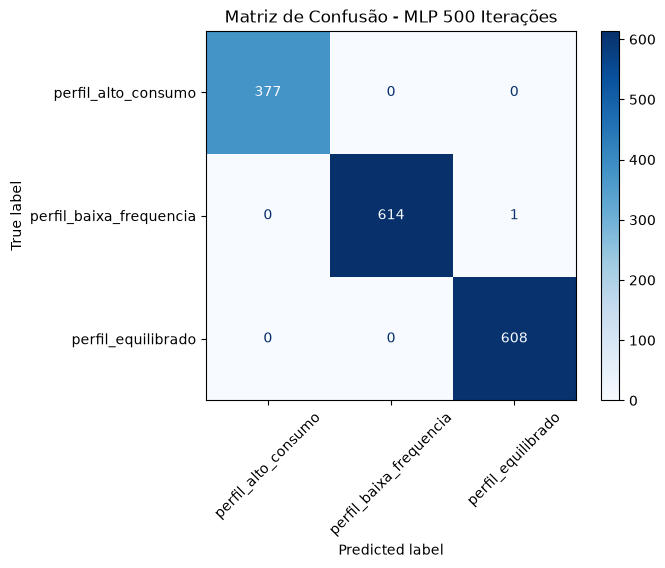

In [52]:
avaliar_modelo(modelo500, x_teste_padronizado, y_teste, nome_modelo="MLP 500 Iterações")

## Modelo de 5000 iterações

### Estrutura do Modelo

In [36]:
modelo5000 = MLPClassifier(
    hidden_layer_sizes = (5,),
    max_iter = 5000,
    tol = 0,
    random_state = 42,
    verbose = True
)

modelo5000.fit(x_treino_padronizado, y_treino)

y_pred_treino = modelo5000.predict(x_treino_padronizado)
acuraciaTreino = accuracy_score(y_treino, y_pred_treino)
print(f"Acurácia de treino do Modelo: {acuraciaTreino: .2%}")

y_pred_teste = modelo5000.predict(x_teste_padronizado)
acuracia = accuracy_score(y_teste, y_pred_teste)
print(f"Acurácia de teste do Modelo: {acuracia: .2%}")

Iteration 1, loss = 1.53098985
Iteration 2, loss = 1.31757363
Iteration 3, loss = 1.15068013
Iteration 4, loss = 1.02367016
Iteration 5, loss = 0.92627297
Iteration 6, loss = 0.85258513
Iteration 7, loss = 0.79580347
Iteration 8, loss = 0.75063351
Iteration 9, loss = 0.71261073
Iteration 10, loss = 0.67884452
Iteration 11, loss = 0.64695403
Iteration 12, loss = 0.61483222
Iteration 13, loss = 0.58076254
Iteration 14, loss = 0.54338484
Iteration 15, loss = 0.50344976
Iteration 16, loss = 0.46402681
Iteration 17, loss = 0.42864728
Iteration 18, loss = 0.39840589
Iteration 19, loss = 0.37255417
Iteration 20, loss = 0.34987064
Iteration 21, loss = 0.32937225
Iteration 22, loss = 0.31060451
Iteration 23, loss = 0.29315600
Iteration 24, loss = 0.27685989
Iteration 25, loss = 0.26156238
Iteration 26, loss = 0.24723536
Iteration 27, loss = 0.23366173
Iteration 28, loss = 0.22094664
Iteration 29, loss = 0.20893365
Iteration 30, loss = 0.19770803
Iteration 31, loss = 0.18711438
Iteration 32, los


--- Detalhes do Treinamento ---
Quantidade real de iterações: 890
Perda final (loss): 0.005075


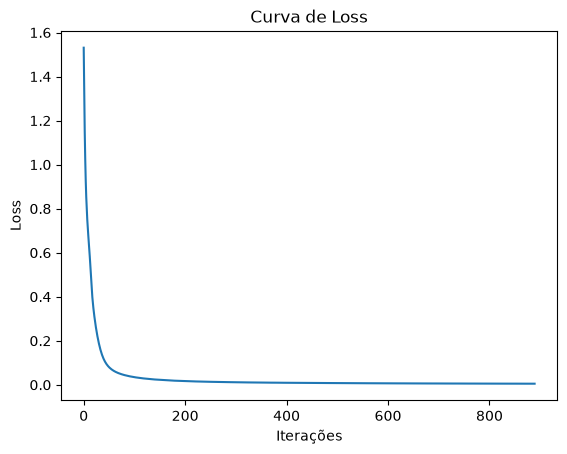

In [11]:
# Atributos de treinamento (disponíveis apenas APÓS o modelo.fit)
print(f"\n--- Detalhes do Treinamento ---")
print(f"Quantidade real de iterações: {modelo5000.n_iter_}")
print(f"Perda final (loss): {modelo5000.loss_:.6f}")

plt.plot(modelo5000.loss_curve_)
plt.xlabel("Iterações")
plt.ylabel("Loss")
plt.title("Curva de Loss")
plt.show()

### Matriz de Confusão


--- Relatório de Classificação: MLP 5000 Iterações ---
                         precision    recall  f1-score   support

    perfil_alto_consumo       1.00      1.00      1.00       377
perfil_baixa_frequencia       1.00      1.00      1.00       615
     perfil_equilibrado       1.00      1.00      1.00       608

               accuracy                           1.00      1600
              macro avg       1.00      1.00      1.00      1600
           weighted avg       1.00      1.00      1.00      1600



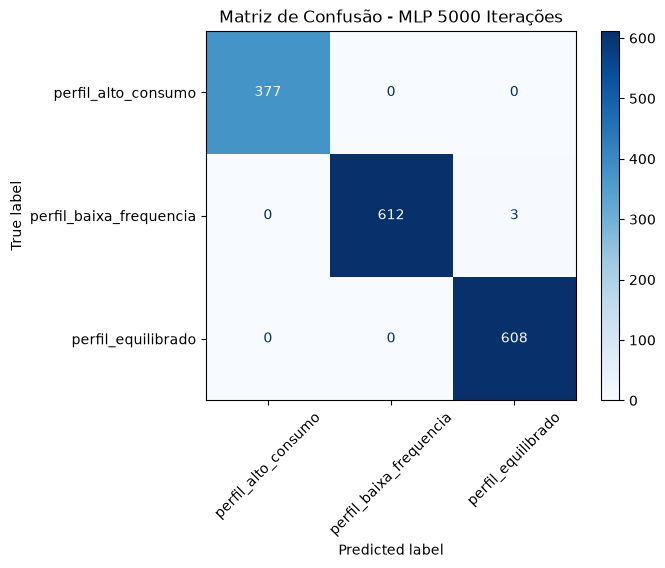

In [53]:
avaliar_modelo(modelo5000, x_teste_padronizado, y_teste, nome_modelo="MLP 5000 Iterações")